# The Power Spectrum

---

> Author: <font color='#f78c40'>Samuel Farrens</font>
> Year: 2026
> Email: [samuel.farrens@cea.fr](mailto:samuel.farrens@cea.fr)
> Website: <a href="https://sfarrens.github.io" target="_blank">https://sfarrens.github.io</a>

## Contents

1. [Set-Up](#Set-Up)
1. [Introduction](#Introduction)
   * [Objective](#Objective)
   * [Notation](#Notation)
1. [The Power Spectrum of a Signal](#The-Power-Spectrum-of-a-Signal)
   * [Definition](#Definition)
   * [What the Power Spectrum Throws Away](#What-the-Power-Spectrum-Throws-Away)
   * [The Wiener-Khinchin Theorem](#The-Wiener-Khinchin-Theorem)
1. [Random Signals](#Random-Signals)
   * [The Power Spectrum of a Random Process](#The-Power-Spectrum-of-a-Random-Process)
   * [Coloured Noise](#Coloured-Noise)
   * [Averaging Periodograms](#Averaging-Periodograms)
1. [Gaussian Random Fields](#Gaussian-Random-Fields)
   * [Making a Field from a Power Spectrum](#Making-a-Field-from-a-Power-Spectrum)
   * [Measuring the Power Spectrum of a Field](#Measuring-the-Power-Spectrum-of-a-Field)
   * [Beyond the Power Spectrum](#Beyond-the-Power-Spectrum)
1. [The Matter Power Spectrum](#The-Matter-Power-Spectrum)
   * [Density Fluctuations](#Density-Fluctuations)
   * [The Two-Point Correlation Function](#The-Two-Point-Correlation-Function)
   * [The Shape of P(k)](#The-Shape-of-P(k))
   * [The BAO Peak](#The-BAO-Peak)
   * [Measuring P(k) in a Survey Volume](#Measuring-P(k)-in-a-Survey-Volume)
1. [The CMB Power Spectrum](#The-CMB-Power-Spectrum)
   * [Fluctuations on the Sphere](#Fluctuations-on-the-Sphere)
   * [The Flat-Sky Approximation](#The-Flat-Sky-Approximation)
   * [The Acoustic Peaks](#The-Acoustic-Peaks)
   * [Observing the CMB: Beam and Noise](#Observing-the-CMB:-Beam-and-Noise)
   * [Masks and Pseudo-Cℓ](#Masks-and-Pseudo-Cℓ)
1. [Weak Lensing and 3x2pt](#Weak-Lensing-and-3x2pt)
   * [Projected Power Spectra](#Projected-Power-Spectra)
   * [The Three Two-Point Functions](#The-Three-Two-Point-Functions)
1. [Exercises](#Exercises)
1. [Summary](#Summary)
1. [Further Resources](#Further-Resources)
1. [Hints](#Hints)

## Set-Up

Here we will import the packages needed throughout the notebook. Plotting and widget code lives in [`ps_plot.py`](ps_plot.py) (which must sit next to this notebook). All of the power-spectrum maths is written out below.

The interactive cells use [ipywidgets](https://ipywidgets.readthedocs.io/) with the [ipympl](https://matplotlib.org/ipympl/) backend, which updates figures in place as you move a slider. If `ipympl` is not installed (`pip install ipympl`), replace `%matplotlib widget` with `%matplotlib inline`: everything still works, but figures are redrawn after each change.

Users new to Jupyter notebooks should note that cells are executed by pressing <kbd>SHIFT</kbd>+<kbd>ENTER</kbd> (&#x21E7;+ &#x23ce;).

In [1]:
# Uncomment the following lines if you are running this on Google Colab.
# !pip install ipympl
# !wget -q https://raw.githubusercontent.com/sfarrens/learning/main/ps_plot.py
# from google.colab import output
# output.enable_custom_widget_manager()

In [2]:
# Interactive matplotlib backend.
%matplotlib widget

# Import the numpy package with the alias np.
import numpy as np

# Import matplotlib (and its bundled sample data).
import matplotlib.pyplot as plt
from matplotlib import cbook

# Import notebook plotting functions and the matter transfer function.
import ps_plot

## Introduction

### <font color='#007acc'>Objective</font>

The Fourier transform describes a signal by the **amplitude** and **phase** of each frequency. The **power spectrum** keeps only the squared amplitude. It tells us *how much variation there is on each scale*, and nothing about *where* that variation is.

For a single, deterministic signal that is a loss of information. For a **random** signal, such as noise, turbulence or the distribution of matter in the Universe, the phases are random and carry no useful information, so the power spectrum is (almost) everything there is to know. This is why it is the central statistic of observational cosmology.

In this notebook we build up the power spectrum from the Fourier transform, learn how to estimate it from noisy data, and then use it to describe two of the most important measurements in cosmology: the **matter power spectrum**, the **CMB power spectrum** and the **3x2pt** power spectra of weak-lensing surveys.

The notebook [The Fourier Transform and Fourier Space](fourier_transform.ipynb) covers the Fourier background used here. For more depth see:

* S. Dodelson and F. Schmidt, [*Modern Cosmology*](https://doi.org/10.1016/C2017-0-01943-2) (2nd ed., 2020)
* W. Hu and S. Dodelson, [*Cosmic Microwave Background Anisotropies*](https://arxiv.org/abs/astro-ph/0110414), ARA&A 40, 171 (2002)

### <font color='#007acc'>Notation</font>

**Time series.** For $N$ samples $x_n$ taken at a rate $f_s$ over a duration $T = N/f_s$, the Discrete Fourier Transform (DFT) is

$$X_k = \sum_{n=0}^{N-1} x_n\, e^{-2\pi i kn/N}, \qquad f_k = \frac{k}{T},$$

where the integer $k$ is the **bin index** and $f_k$ the corresponding frequency in Hz (cycles per second). Each complex coefficient can be written $X_k = |X_k|\, e^{i\phi_k}$, with amplitude $|X_k|$ and phase $\phi_k$. In code, $X_k$ is `np.fft.fft(x)` and $f_k$ is `np.fft.fftfreq(N, 1 / fs)`.

**Fields in space.** From the [Gaussian random fields](#Gaussian-Random-Fields) onwards, signals depend on position $\mathbf{x}$ rather than time, and $k$ takes on its usual meaning in physics and cosmology:

* The **wavenumber** $k = 2\pi/\lambda$ is the spatial frequency of a wave of wavelength $\lambda$, measured in **radians** per unit length. It is the spatial equivalent of the angular frequency $\omega = 2\pi f$.
* In $d$ dimensions, a plane wave $e^{i\mathbf{k}\cdot\mathbf{x}}$ is described by its **wave vector** $\mathbf{k} = (k_x, k_y, \ldots)$, which points perpendicular to the wave crests. Its magnitude $k = |\mathbf{k}|$ is the wavenumber.
* Large $k$ means small scales and small $k$ means large scales. A wavenumber $k$ corresponds to a length scale of about $2\pi/k$.

**Other symbols.** $\overline{z}$ denotes the complex conjugate of $z$, so $|z|^2 = z\overline{z}$, and $\langle \cdot \rangle$ denotes an average over many random realisations (an *ensemble average*).

## The Power Spectrum of a Signal

### <font color='#007acc'>Definition</font>

The **power spectrum** (or *periodogram*, when computed from data) is the squared amplitude of the DFT,

$$P_k = \frac{|X_k|^2}{N^2}.$$

The normalisation is chosen so that, by [Parseval's theorem](https://en.wikipedia.org/wiki/Parseval%27s_theorem) ($\sum_n |x_n|^2 = \frac{1}{N}\sum_k |X_k|^2$), the powers add up to the **mean power** of the signal,

$$\sum_{k=0}^{N-1} P_k = \frac{1}{N}\sum_{n=0}^{N-1} |x_n|^2.$$

For a zero-mean signal this is the **variance**. The power spectrum therefore tells us how the variance of a signal is shared out between frequencies.

> $P_k$ is the power *per bin*. Dividing by the bin width $\Delta f = 1/T$ gives the **power spectral density** (PSD), in units of $[x]^2/\mathrm{Hz}$, which does not depend on the length of the observation. Cosmologists always use a density (see the [matter power spectrum](#The-Matter-Power-Spectrum)).

In [3]:
# Power spectrum (periodogram) of a signal x sampled at a rate fs.
def periodogram(x, fs=1.0):

    X = np.fft.fft(x)
    freqs = np.fft.fftfreq(x.size, d=1 / fs)

    return freqs, np.abs(X) ** 2 / x.size ** 2

Let's take two sine waves, with amplitudes $1$ and $0.5$ at $3$ and $7$ Hz, sampled at 50 Hz for 2 s.

Sum of P_k: 0.6250    Mean of x^2: 0.6250


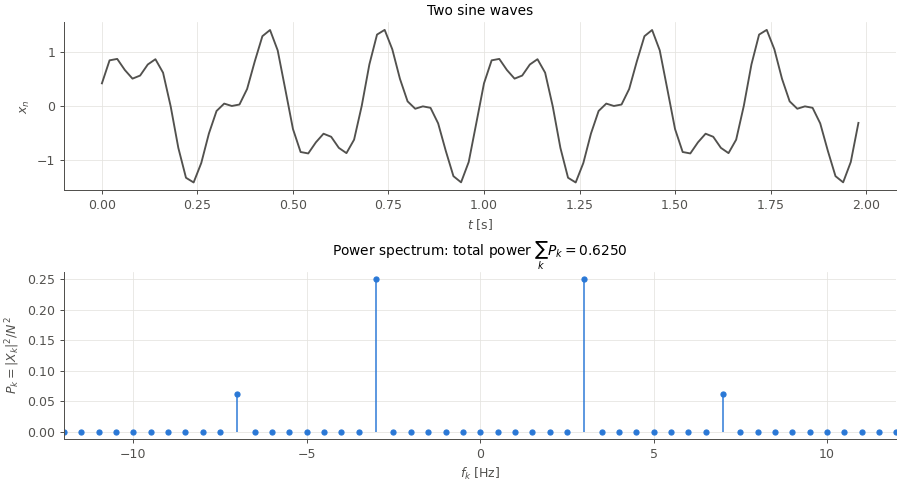

In [4]:
# Sample two sine waves.
fs = 50
t = np.arange(0, 2, 1 / fs)
x = np.sin(2 * np.pi * 3 * t) + 0.5 * np.sin(2 * np.pi * 7 * t + 1.0)

# Compute the power spectrum.
f, P = periodogram(x, fs)

# Check Parseval's theorem: total power = mean square of the signal.
print(f'Sum of P_k: {P.sum():.4f}    Mean of x^2: {np.mean(x ** 2):.4f}')

ps_plot.signal_and_power(t, x, f, P, title='Two sine waves')

A sine wave of amplitude $A$ has mean power $A^2/2$, which is split equally between $\pm f$: $1/4$ at $\pm 3$ Hz and $1/16$ at $\pm 7$ Hz. The phase offset of $1.0$ rad on the second wave leaves no trace in $P_k$.

For a real signal $P_{-k} = P_k$, so plots usually show only the positive frequencies (the *one-sided* spectrum, often multiplied by 2).

### <font color='#007acc'>What the Power Spectrum Throws Away</font>

Squaring the amplitude discards the phase. To see what that costs, let's keep $|X_k|$ but replace every phase $\phi_k$ with a random one. To keep the result real, the random phases must have the same symmetry as the DFT of a real signal, $\phi_{-k} = -\phi_k$. The simplest way to get them is to take them from the DFT of some real white noise.

In [5]:
# Replace the phases of x with random ones, keeping the amplitudes (works in any dimension).
def randomise_phases(x, seed=None):

    rng = np.random.default_rng(seed)
    X = np.fft.fftn(x)
    phases = np.angle(np.fft.fftn(rng.standard_normal(x.shape)))
    # Keep the zero-frequency term (the mean) unchanged.
    phases.flat[0] = np.angle(X.flat[0])

    return np.fft.ifftn(np.abs(X) * np.exp(1j * phases)).real

We will compare the power spectra with a quick radial average (properly defined [later](#Measuring-the-Power-Spectrum-of-a-Field)): for a 2D image, average $|X|^2$ over rings of constant spatial frequency.

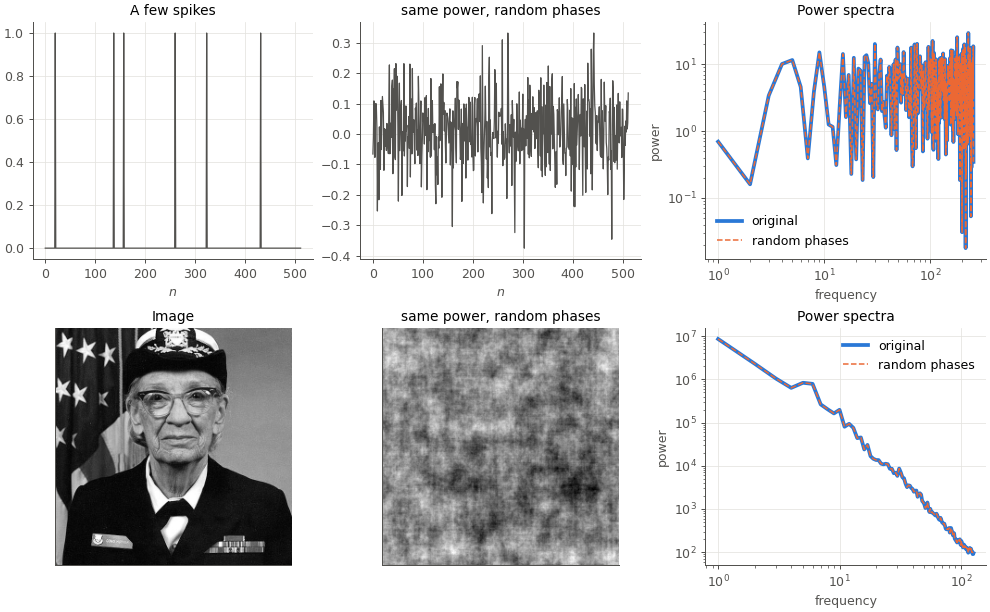

In [6]:
# Load a grey-scale image (256 x 256).
with cbook.get_sample_data('grace_hopper.jpg') as file:
    hopper = plt.imread(file).mean(axis=2)[40:552, :] / 255
hopper = hopper.reshape(256, 2, 256, 2).mean(axis=(1, 3))

# A 1D signal: a few sharp spikes.
spikes = np.zeros(512)
spikes[np.random.default_rng(0).choice(512, 6, replace=False)] = 1.0


# Quick power spectrum: |X|^2 averaged in bins of |frequency| (1D or 2D).
def quick_power(x):

    freq = np.sqrt(sum(f ** 2 for f in np.meshgrid(*[np.fft.fftfreq(n) for n in x.shape], indexing='ij')))
    bins = np.round(freq * x.shape[0]).astype(int).ravel()
    power = np.bincount(bins, np.abs(np.fft.fftn(x).ravel()) ** 2) / np.bincount(bins)

    return np.arange(1, x.shape[0] // 2), power[1:x.shape[0] // 2]


rows = []
for name, signal in (('A few spikes', spikes), ('Image', hopper)):
    scrambled = randomise_phases(signal, seed=0)
    k, power_original = quick_power(signal)
    _, power_scrambled = quick_power(scrambled)
    rows.append((name, signal, scrambled, k, power_original, power_scrambled))

ps_plot.phase_swap(rows)

The power spectra are identical, but all of the *structure* is gone: the spikes and the face are encoded in how the phases of different frequencies line up. With random phases, the signal becomes **noise with the same power spectrum**.

This works both ways. If a signal *is* random noise, its phases are random anyway, and the power spectrum loses nothing that could be predicted. For random signals, $P_k$ is the natural thing to measure.

### <font color='#007acc'>The Wiener-Khinchin Theorem</font>

The **autocorrelation** of a signal measures how similar it is to a shifted copy of itself. For a periodic (circular) signal

$$R_m = \frac{1}{N}\sum_{n=0}^{N-1} x_n\, x_{n+m},$$

where the index $n+m$ wraps around modulo $N$ and the lag is $\tau_m = m/f_s$. The [Wiener-Khinchin theorem](https://en.wikipedia.org/wiki/Wiener%E2%80%93Khinchin_theorem) says that the autocorrelation and the power spectrum are a **Fourier pair**:

$$R_m = \sum_{k=0}^{N-1} P_k\, e^{2\pi i km/N}.$$

It follows directly from the convolution theorem, because a correlation is a convolution with the time-reversed signal. Setting $m = 0$ recovers Parseval's theorem, $R_0 = \sum_k P_k$ (the variance).

So the power spectrum and the autocorrelation contain the same information: one describes the signal by scale (frequency), the other by separation (lag). By the uncertainty principle, a **broad** power spectrum means a **narrow** autocorrelation, and vice versa.

In [7]:
# Circular autocorrelation computed directly from the definition, O(N^2).
def autocorrelation(x):

    return np.array([np.mean(x * np.roll(x, -m)) for m in range(x.size)])


# Circular autocorrelation via the Wiener-Khinchin theorem, O(N log N).
def autocorrelation_wk(x):

    _, P = periodogram(x)

    # np.fft.ifft includes a factor 1 / N, so multiply by N to get sum_k P_k exp(+2 pi i k m / N).
    return (np.fft.ifft(P) * x.size).real

Direct and Wiener-Khinchin results agree: True


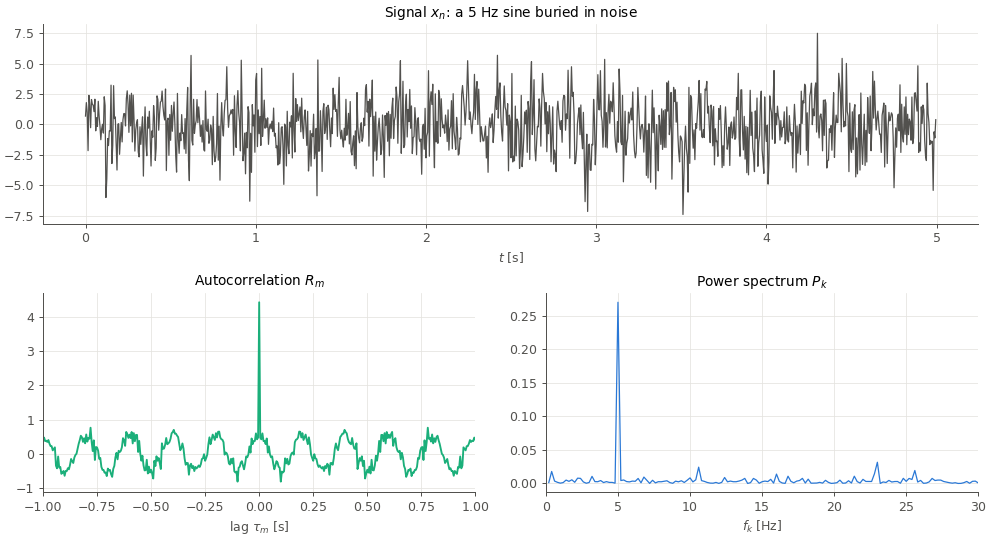

In [8]:
# A 5 Hz sine buried in noise, sampled at 200 Hz for 5 s.
rng = np.random.default_rng(1)
fs = 200
t = np.arange(0, 5, 1 / fs)
x = np.sin(2 * np.pi * 5 * t) + 2 * rng.standard_normal(t.size)

R = autocorrelation_wk(x)
print('Direct and Wiener-Khinchin results agree:', np.allclose(R, autocorrelation(x)))

# Lag of each R_m in seconds (m = 0, 1, ..., then negative lags, in the same order as the DFT).
lags = np.fft.fftfreq(t.size, d=1 / t.size) / fs
f, P = periodogram(x, fs)
ps_plot.autocorrelation_plot(t, x, lags, R, f, P)

The sine is invisible in the signal, but obvious in both of the other panels. In the autocorrelation the noise only correlates with itself at zero lag (a single spike at $\tau = 0$, of height $\sigma^2 = 4$), while the sine keeps correlating at every multiple of its period. In the power spectrum the noise is a flat floor and the sine is a single peak. Searching for periodic signals in noisy data, *e.g.* pulsars or exoplanet transits, uses exactly this idea.

## Random Signals

### <font color='#007acc'>The Power Spectrum of a Random Process</font>

A random signal, such as the noise above, is one *realisation* of a random process. If we repeated the experiment we would get a different signal, with different $X_k$. What stays the same is the **expected** power,

$$P(f_k) = \langle P_k \rangle = \frac{\langle |X_k|^2 \rangle}{N^2}.$$

This is the *true* power spectrum of the process. It is well defined if the process is **stationary**, *i.e.* its statistical properties do not change with time. Different frequencies are then uncorrelated, $\langle X_k \overline{X_{k'}} \rangle = 0$ for $k \neq k'$, and each one is described by its variance alone.

The periodogram of one realisation is only an **estimate** of $P(f)$, and a very noisy one. For Gaussian noise each $X_k$ is a complex Gaussian with a random phase, so $P_k$ follows an exponential distribution, whose standard deviation equals its mean:

$$\frac{\sigma_{P_k}}{P(f_k)} = 1.$$

A longer observation does not help: it gives *more* bins, each one just as noisy. We will see how to fix this [below](#Averaging-Periodograms).

### <font color='#007acc'>Coloured Noise</font>

**White noise** has the same power at all frequencies (like white light). Many signals have a **power-law** spectrum, $P(f) \propto f^{-\beta}$. The exponent is called the **spectral index**. On a log-log plot a power law is a straight line, and the spectral index is minus its slope:

$$\beta = -\frac{d\ln P}{d\ln f}.$$

For spectra that are not exact power laws, this logarithmic derivative defines a *local* spectral index, which can change with frequency. The sign convention varies between fields: the noise literature writes $f^{-\beta}$, while cosmology writes $k^{n}$ (so $n = -\beta$), *e.g.* the primordial spectral index $n_s$ [below](#The-Shape-of-P(k)).

Noise is named by analogy with colour, according to its spectral index:

| $\beta$ | Name | Examples |
|:--|:--|:--|
| $0$ | White | Thermal (Johnson) noise, photon shot noise |
| $1$ | Pink, or $1/f$ | Detector drifts, electronics flicker noise, many natural signals |
| $2$ | Brown (red) | A random walk (Brownian motion), atmospheric fluctuations |

To make noise with any power spectrum, start from white noise and multiply its DFT by $\sqrt{P(f)}$, which shapes the amplitudes but leaves the phases random.

In [9]:
# Gaussian noise with P(f) proportional to f^-beta, normalised to unit variance.
def coloured_noise(N, beta, seed=None):

    rng = np.random.default_rng(seed)
    f = np.fft.fftfreq(N)

    # Amplitude scaling sqrt(P) = |f|^(-beta / 2), with the f = 0 term (the mean) set to zero.
    scale = np.zeros(N)
    scale[1:] = np.abs(f[1:]) ** (-beta / 2)

    x = np.fft.ifft(np.fft.fft(rng.standard_normal(N)) * scale).real

    return x / x.std()

In the cell below, change $\beta$ to see and *hear* the different colours of noise. The periodogram (grey) scatters by 100% around the true spectrum (orange), whatever the slope. On a log scale this shows up as a band of constant width.

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [10]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ps_plot.coloured_noise_demo(coloured_noise, periodogram)

Increasing $\beta$ moves the power to low frequencies, so the signal wanders slowly: white noise hisses, pink noise sounds like rain or a waterfall, and brown noise rumbles. Negative $\beta$ (blue noise) does the opposite.

### <font color='#007acc'>Averaging Periodograms</font>

To reduce the scatter we must average over independent estimates. **Bartlett's method** splits the data into $M$ segments, computes a periodogram for each and averages them. The scatter drops to

$$\frac{\sigma_P}{P} = \frac{1}{\sqrt{M}},$$

but each segment is $M$ times shorter, so the frequency resolution becomes $M$ times worse, $\Delta f = M/T$. **Welch's method** improves on this with overlapping, windowed segments, and is what `scipy.signal.welch` implements.

There is always a trade-off between **resolution** and **precision**. Averaging the neighbouring bins of a single periodogram achieves the same thing. This is exactly what cosmologists do when they average over all the modes with the same wavenumber $|\mathbf{k}|$.

In [11]:
# Bartlett's method: average the periodograms of M non-overlapping segments.
def bartlett(x, M, fs=1.0):

    segments = x[:x.size // M * M].reshape(M, -1)
    freqs, _ = periodogram(segments[0], fs)
    power = np.mean([periodogram(segment, fs)[1] for segment in segments], axis=0)

    return freqs, power

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [12]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ps_plot.averaging_demo(coloured_noise, bartlett)

With $M = 1$ the estimate fills a band an order of magnitude wide. As $M$ grows, it converges onto the true $1/f$ spectrum, but the lowest frequencies disappear: a segment of length $T/M$ cannot measure anything slower than $M/T$.

## Gaussian Random Fields

### <font color='#007acc'>Making a Field from a Power Spectrum</font>

Everything so far carries over to 2D and 3D. A **random field** $\delta(\mathbf{x})$ is a random signal that depends on position. If it is **statistically homogeneous** (the same everywhere, the spatial version of stationarity) and **isotropic** (the same in every direction), its power spectrum depends only on the magnitude of the wave vector, $k = |\mathbf{k}|$:

$$P(k) \propto \langle |\delta_{\mathbf{k}}|^2 \rangle.$$

In a **Gaussian random field** (GRF) every Fourier mode $\delta_{\mathbf{k}}$ is an independent complex Gaussian with variance $\propto P(k)$ and a uniformly random phase. A GRF is *completely* described by its power spectrum. To make one, we do the same as for coloured noise: multiply the Fourier transform of white noise by $\sqrt{P(k)}$.

Here, and in the rest of the notebook, we use the cosmology conventions:

* The field is sampled on an $N^d$ grid covering a box of side $L$ in $d$ dimensions, with cell volume $V_{\rm cell} = (L/N)^d$ and total volume $V = L^d$.
* The wavenumber is measured in **radians** per unit length, $k = 2\pi \times$ `fftfreq(N, L / N)`. It ranges from the **fundamental mode** $k_{\rm f} = 2\pi/L$ (one wave across the box) to the **Nyquist frequency** $k_{\rm Ny} = \pi N/L$ (two cells per wave).
* $P(k)$ is a power spectral *density*, with units of volume. It is normalised so that the variance of the field is $\langle \delta^2 \rangle = \frac{1}{V}\sum_{\mathbf{k}} P(k)$, the sum running over all $N^d$ modes. The discrete transform needs a factor $V_{\rm cell}$ to approximate the continuous one, which is where the factors of $V_{\rm cell}$ below come from.

In [13]:
# Magnitude of the wave vector, |k|, on an N^d grid with box size L (radians per unit length).
def wavenumbers(N, L, ndim):

    k1d = 2 * np.pi * np.fft.fftfreq(N, d=L / N)

    return np.sqrt(sum(k ** 2 for k in np.meshgrid(*[k1d] * ndim, indexing='ij')))


# Gaussian random field on an N^d grid of side L with power spectrum power(k).
def gaussian_random_field(N, L, power, ndim=2, seed=None):

    rng = np.random.default_rng(seed)
    k = wavenumbers(N, L, ndim)
    cell = (L / N) ** ndim

    # Power at each mode (zero for the k = 0 mode, so the field has zero mean).
    P = np.zeros_like(k)
    P[k > 0] = power(k[k > 0])

    # White noise has <|W_k|^2> = N^d, so scaling by sqrt(P / cell) gives <|delta_k|^2> = N^d P / cell.
    white = np.fft.fftn(rng.standard_normal(k.shape))

    return np.fft.ifftn(white * np.sqrt(P / cell)).real

### <font color='#007acc'>Measuring the Power Spectrum of a Field</font>

To estimate $P(k)$ from a field we invert the recipe: compute $|\delta_{\mathbf{k}}|^2$ for every mode, then average all the modes that fall in a thin shell (in 2D, a ring) of constant $|\mathbf{k}|$,

$$\hat{P}(k) = \frac{V_{\rm cell}^2}{V}\, \frac{1}{N_{\rm modes}(k)} \sum_{|\mathbf{k}| \in \text{shell}} |\delta_{\mathbf{k}}|^2.$$

Averaging over the $N_{\rm modes}$ in a shell plays the role of averaging periodograms. Since the field is real, $\delta_{-\mathbf{k}} = \overline{\delta_{\mathbf{k}}}$, so only half of the modes are independent. The scatter on the estimate is therefore

$$\frac{\sigma_P}{P} = \sqrt{\frac{2}{N_{\rm modes}}}.$$

A shell of width $\Delta k$ contains $N_{\rm modes} \propto k^{d-1}\Delta k$ modes, so **large scales (small $k$) are always measured less precisely**: there are only a few independent large waves in the box. This is called **sample variance**, or **cosmic variance** when the box is the whole observable Universe.

In [14]:
# Radially averaged power spectrum of a field (any dimension) with box size L.
def radial_power_spectrum(field, L, n_bins=None):

    N, ndim = field.shape[0], field.ndim
    cell, volume = (L / N) ** ndim, L ** ndim

    # Power of every mode and its wavenumber.
    power = cell ** 2 * np.abs(np.fft.fftn(field)) ** 2 / volume
    k = wavenumbers(N, L, ndim)

    # Linear bins from half the fundamental mode up to the Nyquist frequency.
    k_f, k_ny = 2 * np.pi / L, np.pi * N / L
    n_bins = n_bins or N // 2
    edges = np.linspace(k_f / 2, k_ny, n_bins + 1)
    index = np.digitize(k.ravel(), edges) - 1
    valid = (index >= 0) & (index < n_bins)

    # Average the power (and k) of the modes in each bin.
    n_modes = np.bincount(index[valid], minlength=n_bins)
    k_mean = np.bincount(index[valid], k.ravel()[valid], n_bins) / np.maximum(n_modes, 1)
    p_mean = np.bincount(index[valid], power.ravel()[valid], n_bins) / np.maximum(n_modes, 1)
    keep = n_modes > 0

    return k_mean[keep], p_mean[keep], n_modes[keep]

In the cell below, the field is $256 \times 256$ pixels with $L = N$, so $k$ is in radians per pixel. Change the spectral index $n$ of a power law $P(k) \propto k^n$ (the cosmology sign convention, so $n = -\beta$) and look at the field.

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [15]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ps_plot.grf_demo(gaussian_random_field, radial_power_spectrum)

* $n = 0$ is white noise: every scale contributes equally, so the field looks like static.
* Negative $n$ puts more power on large scales, giving larger and larger blobs. Many natural fields are power laws, *e.g.* $n = -11/3$ for the velocity field of 3D turbulence ([Kolmogorov 1941](https://en.wikipedia.org/wiki/Energy_cascade)), and $n \approx -2.7$ for maps of Galactic dust emission.
* Changing the seed changes the phases (*which* blobs are where) but not the statistics.
* The measured points scatter most at small $k$, where the rings contain the fewest modes.

### <font color='#007acc'>Beyond the Power Spectrum</font>

A GRF is fully described by $P(k)$, but most fields are not Gaussian. Let's build a field of randomly placed discs, then randomise its phases. The two have exactly the same power spectrum.

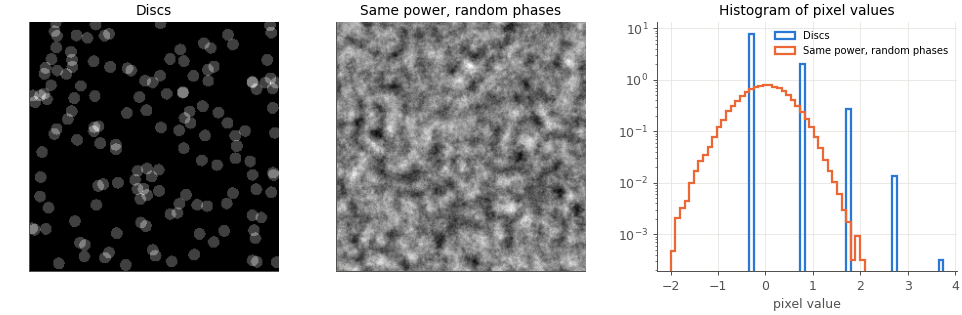

In [16]:
# A field of 150 randomly placed discs (zero mean).
rng = np.random.default_rng(2)
y, x = np.mgrid[:256, :256]
discs = np.zeros((256, 256))
for cx, cy in rng.uniform(0, 256, (150, 2)):
    discs += (np.hypot(x - cx, y - cy) < 6).astype(float)
discs -= discs.mean()

# Compare with the same field after randomising its phases.
ps_plot.pdf_comparison([discs, randomise_phases(discs, seed=0)], ['Discs', 'Same power, random phases'])

The randomised field is Gaussian (a parabola on the log-scale histogram), while the discs have only a few distinct pixel values. The power spectrum cannot tell them apart. Information about shapes, peaks and filaments lives in the phases, and needs **higher-order statistics** such as the bispectrum (three-point function), peak counts, Minkowski functionals or wavelet-based statistics.

This matters in cosmology:

* The early Universe, as seen in the CMB, is Gaussian to high precision (Planck finds no primordial non-Gaussianity), so its power spectrum is essentially a complete description.
* Gravity makes the late-time matter distribution increasingly non-Gaussian (a *cosmic web* of filaments and halos), so a lot of information leaks out of $P(k)$ on small scales.

## The Matter Power Spectrum

### <font color='#007acc'>Density Fluctuations</font>

The Universe is homogeneous on the largest scales, but not on smaller ones. We describe the inhomogeneities by the **density contrast**

$$\delta(\mathbf{x}) = \frac{\rho(\mathbf{x}) - \bar{\rho}}{\bar{\rho}},$$

where $\bar{\rho}$ is the mean density. With the Fourier transform $\delta(\mathbf{k}) = \int \delta(\mathbf{x})\, e^{-i\mathbf{k}\cdot\mathbf{x}}\, d^3x$, the **matter power spectrum** $P(k)$ is defined by

$$\langle \delta(\mathbf{k})\, \overline{\delta(\mathbf{k}')} \rangle = (2\pi)^3\, \delta_{\rm D}(\mathbf{k} - \mathbf{k}')\, P(k).$$

The Dirac delta $\delta_{\rm D}$ says that different modes are uncorrelated (homogeneity), and $P$ depending only on $k = |\mathbf{k}|$ expresses isotropy. This is the continuous version of the GRF definition above.

* $k$ is in $h\,\mathrm{Mpc}^{-1}$ and $P(k)$ in $h^{-3}\,\mathrm{Mpc}^3$, where $h \approx 0.67$ is the Hubble constant in units of $100\ \mathrm{km\,s^{-1}\,Mpc^{-1}}$. A wavenumber $k$ corresponds to a scale of about $2\pi/k$.
* The **dimensionless power spectrum** $\Delta^2(k) = k^3 P(k)/2\pi^2$ is the contribution to the variance of $\delta$ per logarithmic interval in $k$, $\langle\delta^2\rangle = \int \Delta^2(k)\, d\ln k$. Structure is nonlinear where $\Delta^2 \gtrsim 1$.
* The overall amplitude is usually quoted as $\sigma_8$: the root-mean-square of $\delta$ in spheres of radius $8\,h^{-1}\,\mathrm{Mpc}$,

$$\sigma_8^2 = \int \Delta^2(k)\, W^2(kR)\, d\ln k, \qquad W(x) = \frac{3(\sin x - x\cos x)}{x^3}, \quad R = 8\,h^{-1}\,\mathrm{Mpc},$$

where $W$ is the Fourier transform of a spherical top-hat.

### <font color='#007acc'>The Two-Point Correlation Function</font>

We do not observe $\delta(\mathbf{x})$ directly. We observe **galaxies**: a set of points that trace the underlying density. The simplest way to describe how points cluster is the **two-point correlation function** $\xi(r)$, the *excess* probability, compared with a random distribution, of finding a pair of points at separation $r$:

$$dP = \bar{n}^2\, [1 + \xi(r)]\, dV_1\, dV_2,$$

where $\bar{n}$ is the mean number density. For the density field, $\xi(r) = \langle \delta(\mathbf{x})\, \delta(\mathbf{x} + \mathbf{r}) \rangle$.

* $\xi > 0$: pairs are more common than at random (**clustering**).
* $\xi = 0$: no correlation (a **Poisson** process).
* $\xi < 0$: pairs are rarer than at random (**anti-clustering**, *e.g.* points that repel each other).

By the Wiener-Khinchin theorem, $\xi$ and $P$ are a **Fourier pair**: they contain the same information, one in terms of separations, the other in terms of scales. For an isotropic field, the angular part of the Fourier integral can be done analytically, which gives

$$\xi(r) = \int_0^\infty \frac{k^2 dk}{2\pi^2}\, P(k)\, \frac{\sin kr}{kr} \quad \text{(3D)}, \qquad \xi(r) = \int_0^\infty \frac{k\, dk}{2\pi}\, P(k)\, J_0(kr) \quad \text{(2D)},$$

where $J_0$ is a Bessel function. These are sometimes called *Hankel transforms*.

**Estimators.** From a catalogue of $N$ points in a box of area (or volume) $V$, we estimate:

* $\hat{\xi}(r)$ by counting the pairs $DD(r)$ in bins of separation, and comparing with the number expected for random points, $RR(r) = \frac{N(N-1)}{2} \frac{V_{\rm bin}(r)}{V}$, where $V_{\rm bin}$ is the area (or volume) of the shell of radii $r$ to $r + \Delta r$. Then $\hat{\xi} = DD/RR - 1$. Real surveys use random catalogues and the Landy-Szalay estimator to deal with the survey edges.
* $\hat{P}(k)$ by counting the points in each cell of a grid, converting the counts to a density contrast $\delta = n/\bar{n} - 1$, and using the `radial_power_spectrum` estimator from before.

Points are discrete, so even a perfectly random distribution has power: the **shot noise** $P_{\rm shot} = 1/\bar{n}$. It is the power spectrum of white noise, and it is the point-process equivalent of a noise floor. In the correlation function it only appears at $r = 0$ (each point paired with itself), which is why pair counts exclude self-pairs.

In [17]:
# Two-point correlation function of points in a periodic 2D box of side L, in bins of separation.
def pair_correlation(points, L, r_edges):

    # Separation of every pair, using the nearest periodic copy (the minimum-image convention).
    d = points[:, None, :] - points[None, :, :]
    d -= L * np.round(d / L)
    r = np.hypot(d[..., 0], d[..., 1])

    # Data-data pair counts (each pair appears twice in r; self-pairs at r = 0 fall outside the bins).
    DD = np.histogram(r, r_edges)[0] / 2

    # Expected counts for random points: number of pairs times the fraction of the area in each annulus.
    n = len(points)
    RR = n * (n - 1) / 2 * np.pi * np.diff(r_edges ** 2) / L ** 2

    return np.sqrt(r_edges[1:] * r_edges[:-1]), DD / RR - 1


# Power spectrum of points in a periodic 2D box of side L, assigned to an n_grid x n_grid grid.
def point_power_spectrum(points, L, n_grid=256):

    counts = np.histogram2d(points[:, 0], points[:, 1], bins=n_grid, range=[[0, L], [0, L]])[0]
    delta = counts / counts.mean() - 1

    return radial_power_spectrum(delta, L)

Let's make four distributions of about 2000 points in a periodic unit box ($L = 1$):

* **Random:** a Poisson process, every point placed independently.
* **Clustered:** a *Thomas process*, with 45 cluster centres, each surrounded by 45 points with a Gaussian scatter of width $\sigma$. This is a toy version of galaxies living in dark-matter halos.
* **Filaments:** points scattered along 45 random line segments, a toy version of the cosmic web.
* **Regular:** a $45\times45$ grid, with each point randomly displaced by 20% of the spacing.

For the clustered case we can work out $\xi$ and $P$ analytically. Two points in the same cluster are separated by the difference of two Gaussian offsets, a Gaussian of variance $2\sigma^2$. With $n_c$ clusters per unit area, each of $m$ points,

$$\xi(r) = \frac{m-1}{m\,n_c}\, \frac{e^{-r^2/4\sigma^2}}{4\pi\sigma^2}, \qquad P(k) = \frac{m-1}{m\,n_c}\, e^{-k^2\sigma^2}.$$

The Fourier transform of a Gaussian is a Gaussian: the narrower the clusters, the further their power extends to high $k$.

In [18]:
rng = np.random.default_rng(4)
L_box, n_side = 1.0, 45

# Random (Poisson).
random_points = rng.uniform(0, L_box, (n_side ** 2, 2))

# Clustered (Thomas process): n_side clusters of n_side points with Gaussian scatter sigma_c.
sigma_c = 0.015
centres = rng.uniform(0, L_box, (n_side, 2))
clustered_points = (np.repeat(centres, n_side, axis=0) + sigma_c * rng.standard_normal((n_side ** 2, 2))) % L_box

# Filaments: points along n_side random segments of length 0.3, with a small perpendicular scatter.
starts = np.repeat(rng.uniform(0, L_box, (n_side, 2)), n_side, axis=0)
angles = np.repeat(rng.uniform(0, np.pi, n_side), n_side)
t = rng.uniform(0, 0.3, n_side ** 2)
filament_points = (starts + t[:, None] * np.c_[np.cos(angles), np.sin(angles)]
                   + 0.003 * rng.standard_normal((n_side ** 2, 2))) % L_box

# Regular: a perturbed grid.
spacing = L_box / n_side
grid = (np.stack(np.meshgrid(np.arange(n_side), np.arange(n_side)), axis=-1).reshape(-1, 2) + 0.5) * spacing
regular_points = (grid + 0.2 * spacing * rng.standard_normal(grid.shape)) % L_box

distributions = {
    'Random': random_points,
    'Clustered': clustered_points,
    'Filaments': filament_points,
    'Regular': regular_points,
}

# Analytic xi(r) and P(k) (without shot noise) for the random and clustered cases.
amplitude = (n_side - 1) / (n_side * n_side / L_box ** 2)
theory = {
    'Random': (lambda r: 0 * r, lambda k: 0 * k),
    'Clustered': (lambda r: amplitude * np.exp(-r ** 2 / (4 * sigma_c ** 2)) / (4 * np.pi * sigma_c ** 2),
                  lambda k: amplitude * np.exp(-(k * sigma_c) ** 2)),
}

In the cell below, use the dropdown to switch between the distributions, and compare how the correlation function (middle) and the power spectrum (right) change.

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [19]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ps_plot.points_demo(distributions, L_box, pair_correlation, point_power_spectrum, theory)

* **Random.** $\hat{\xi}$ scatters around zero, and $\hat{P}$ is flat at the shot-noise level $1/\bar{n}$: pure white noise.
* **Clustered.** $\xi$ is large at separations smaller than the cluster size, and zero beyond. In Fourier space this is excess power at $k \lesssim 1/\sigma_c$, on top of the shot noise. The measurements follow the analytic Fourier pair. With only 45 clusters, chance alignments between clusters add some scatter on large scales (large $r$, small $k$).
* **Filaments.** The correlation is spread over a range of scales, and $\xi$ falls off roughly as a power law. A line has $P \propto 1/k$ in 2D, which you can see at intermediate $k$. The power spectrum cannot tell you that the structures are filaments rather than elongated clusters: that information is in the phases.
* **Regular.** $\xi \to -1$ at small $r$: no two points are closer than about the spacing allows. The power drops *below* the shot noise at small $k$, because a regular distribution has smaller density fluctuations on large scales than a random one. The spike near $k = 2\pi/\text{spacing} \approx 280$ is the grid itself.

In every case, $\xi$ and $P$ tell the same story in different languages. Large separations in $\xi$ correspond to small $k$ in $P$.

### <font color='#007acc'>The Shape of P(k)</font>

To a good approximation, the linear matter power spectrum today is

$$P(k) = A\, k^{n_s}\, T^2(k).$$

* **Primordial spectrum, $k^{n_s}$.** The **scalar spectral index** $n_s$ is the spectral index of the initial density fluctuations. Inflation predicts a nearly scale-invariant spectrum of initial fluctuations, $n_s \approx 1$ (the Harrison-Zel'dovich spectrum, for which $\Delta^2$ of the gravitational potential is the same on all scales). Planck measures $n_s = 0.965$.
* **Transfer function, $T(k)$.** Describes how fluctuations grew after inflation. Modes that entered the horizon while the Universe was dominated by radiation, before **matter-radiation equality**, barely grew, because radiation pressure prevents collapse. This gives a **turnover** at the horizon scale at equality, $k_{\rm eq} \approx 0.073\,\Omega_m h^2\ \mathrm{Mpc}^{-1}$: $P \propto k^{n_s}$ on large scales and $P \propto k^{n_s - 4}\ln^2 k$ on small scales.
* **Baryon acoustic oscillations (BAO).** Before recombination, baryons and photons formed a single fluid that oscillated as sound waves. These were frozen in at a characteristic scale, the **sound horizon** $r_s \approx 147\ \mathrm{Mpc} \approx 100\,h^{-1}\,\mathrm{Mpc}$, leaving small wiggles in $P(k)$ with period $\Delta k \approx 2\pi/r_s$. Baryons also slightly suppress power on small scales.
* **Amplitude, $A$.** Fixed by $\sigma_8 \approx 0.81$.

Computing $T(k)$ exactly requires solving the coupled Boltzmann equations for photons, baryons, dark matter and neutrinos (with codes such as [CAMB](https://camb.info) or [CLASS](https://lesgourg.github.io/class_public/class.html)). Here we use the [Eisenstein & Hu (1998)](https://arxiv.org/abs/astro-ph/9709112) fitting formula with simplified BAO wiggles, provided by `ps_plot.transfer_function`. It depends on the matter density $\Omega_m$ and the baryon fraction $f_b = \Omega_b/\Omega_m$.

In [20]:
# Fourier transform of a spherical top-hat window.
def tophat_window(x):

    return 3 * (np.sin(x) - x * np.cos(x)) / x ** 3


# Linear matter power spectrum today [h^-3 Mpc^3] for k in h/Mpc, normalised to sigma_8.
def matter_power(k, Omega_m=0.315, f_b=0.157, n_s=0.965, sigma_8=0.811, wiggles=True):

    shape = lambda q: q ** n_s * ps_plot.transfer_function(q, Omega_m, f_b, wiggles=wiggles) ** 2

    # sigma_8^2 = integral of Delta^2(k) W^2(kR) dln k, on a logarithmic grid in k.
    q = np.logspace(-4, 2, 2000)
    delta2 = q ** 3 * shape(q) / (2 * np.pi ** 2)
    sigma2 = np.sum(delta2 * tophat_window(8 * q) ** 2) * np.log(q[1] / q[0])

    return sigma_8 ** 2 / sigma2 * shape(k)

### <font color='#007acc'>The BAO Peak</font>

The 3D correlation function of the matter field follows from $P(k)$ through the Hankel transform above. In terms of $\Delta^2(k)$,

$$\xi(r) = \int \Delta^2(k)\, \frac{\sin kr}{kr}\, d\ln k.$$

The integrand oscillates and decays slowly, so for numerical purposes we multiply it by a Gaussian $e^{-k^2\sigma^2}$, which smooths $\xi$ on a scale $\sigma = 1\,h^{-1}\,\mathrm{Mpc}$, well below the scales of interest. In $\xi(r)$ the BAO wiggles all add up into a single **peak** at $r_s$: the size of the frozen sound wave. Galaxies are slightly more likely to be found $\approx 100\,h^{-1}\,\mathrm{Mpc}$ apart than at slightly smaller or larger separations.

In [21]:
# Correlation function xi(r) from P(k) (Wiener-Khinchin in 3D), with k on a logarithmic grid.
def correlation_function(r, k, P, smoothing=1.0):

    delta2 = k ** 3 * P / (2 * np.pi ** 2) * np.exp(-(k * smoothing) ** 2)

    # np.sinc(x) = sin(pi x) / (pi x), so np.sinc(k r / pi) = sin(k r) / (k r).
    integrand = delta2 * np.sinc(np.outer(r, k) / np.pi)

    return integrand.sum(axis=1) * np.log(k[1] / k[0])

In the cell below, change the cosmological parameters and see how $P(k)$ (top), the BAO wiggles (bottom left) and $\xi(r)$ (bottom right) respond. The grey curves show the Planck 2018 values.

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [22]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ps_plot.matter_demo(matter_power, correlation_function)

Try the following:

* **Increase $\Omega_m$.** Equality happens earlier, when the horizon was smaller, so the turnover moves to larger $k$ (smaller scales). The sound horizon also shrinks, so the BAO peak moves to smaller $r$. This is how galaxy surveys measure $\Omega_m$.
* **Increase $f_b$.** The wiggles and the BAO peak grow, and small-scale power is suppressed. With $f_b \to 0$ (dark matter only) the wiggles disappear.
* **Change $n_s$.** The spectrum tilts around the scales that determine $\sigma_8$.

The BAO peak is a **standard ruler**: its comoving size, $r_s$, is known from the physics of the early Universe (and measured precisely by the CMB). Measuring its apparent size at different redshifts maps out the expansion history of the Universe, which is one of the main goals of surveys such as DESI and *Euclid*.

### <font color='#007acc'>Measuring P(k) in a Survey Volume</font>

Let's simulate a Gaussian density field in a cubic box of $L = 1\,h^{-1}\,\mathrm{Gpc}$ on a $128^3$ grid, using `matter_power` as the input spectrum, and measure its power spectrum with exactly the same `radial_power_spectrum` function as before. The grid covers $k_{\rm f} = 0.006$ to $k_{\rm Ny} = 0.4\,h\,\mathrm{Mpc}^{-1}$.

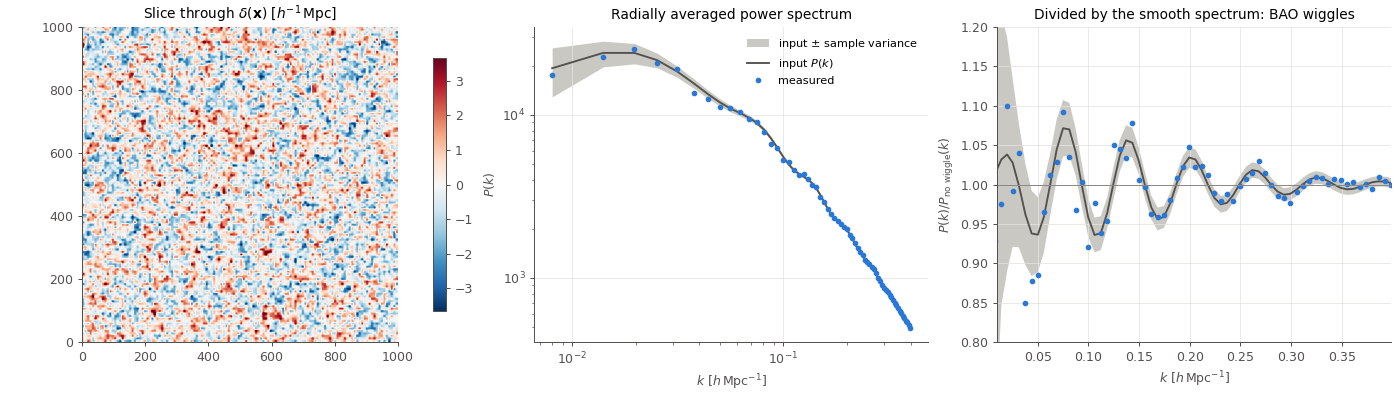

In [23]:
# Box size [Mpc/h] and grid size.
L, N = 1000, 128

# Simulate a 3D Gaussian density field with the matter power spectrum.
delta = gaussian_random_field(N, L, matter_power, ndim=3, seed=5)

# Measure its power spectrum, and evaluate the input spectrum at the same k.
k, P_measured, n_modes = radial_power_spectrum(delta, L)
P_input = matter_power(k)
P_smooth = matter_power(k, wiggles=False)

ps_plot.field_and_spectrum(
    delta[:, :, N // 2], k, P_measured, P_input, n_modes,
    title=r'Slice through $\delta(\mathbf{x})$ [$h^{-1}\,$Mpc]', extent=[0, L, 0, L],
    k_label=r'$k$ [$h\,$Mpc$^{-1}$]', ratio_to=P_smooth,
)

The measurement follows the input within the expected scatter. On large scales the error bars blow up, because a 1 Gpc box only contains a handful of waves that large. Dividing by the smooth spectrum (right) shows that a single box of this size only *hints* at the BAO wiggles.

The precision scales as $1/\sqrt{N_{\rm modes}} \propto 1/\sqrt{V}$, which is why BAO surveys map tens of $h^{-3}\,\mathrm{Gpc}^3$. Real galaxy surveys also have to deal with:

* **galaxy bias**: galaxies trace the matter, $\delta_g \approx b\,\delta$, so $P_g = b^2 P$
* **shot noise**: galaxies are discrete points, which adds a white-noise term $1/\bar{n}$, where $\bar{n}$ is the number density
* **redshift-space distortions**: peculiar velocities distort distances along the line of sight, making $P$ anisotropic
* **nonlinear growth**: on small scales ($k \gtrsim 0.1\,h\,\mathrm{Mpc}^{-1}$ today) gravity adds power, smears the BAO and makes the field non-Gaussian
* **the survey window**: the observed volume is not a periodic cube, which convolves $P(k)$ with the window's power spectrum (the spectral leakage of cosmology).

## The CMB Power Spectrum

### <font color='#007acc'>Fluctuations on the Sphere</font>

The cosmic microwave background (CMB) is light emitted at recombination, about 380,000 years after the Big Bang. It has a nearly perfect black-body spectrum with $T_0 = 2.7255\ \mathrm{K}$, and tiny fluctuations, $\Delta T(\hat{\mathbf{n}})$, of about $100\ \mu\mathrm{K}$ in direction $\hat{\mathbf{n}}$.

On a sphere, the role of sines and cosines is played by the **spherical harmonics** $Y_{\ell m}$:

$$\Delta T(\hat{\mathbf{n}}) = \sum_{\ell=0}^{\infty} \sum_{m=-\ell}^{\ell} a_{\ell m}\, Y_{\ell m}(\hat{\mathbf{n}}).$$

* The **multipole** $\ell$ plays the role of frequency: $Y_{\ell m}$ oscillates on an angular scale $\theta \approx 180°/\ell$.
* $m$ describes orientation. For each $\ell$ there are $2\ell + 1$ values of $m$.

For a statistically isotropic sky, the **angular power spectrum** is

$$\langle a_{\ell m}\, \overline{a_{\ell' m'}} \rangle = \delta_{\ell\ell'}\, \delta_{mm'}\, C_\ell,$$

and it is usually plotted as $\mathcal{D}_\ell = \ell(\ell+1)C_\ell/2\pi$, in $\mu\mathrm{K}^2$. Like $\Delta^2(k)$, $\mathcal{D}_\ell$ is the contribution to the variance of the map per logarithmic interval in $\ell$.

We only have one sky. At each $\ell$ we can average over just $2\ell + 1$ independent modes, so even a perfect measurement has an irreducible uncertainty, the **cosmic variance**

$$\frac{\Delta C_\ell}{C_\ell} = \sqrt{\frac{2}{2\ell + 1}}.$$

At $\ell = 2$ (the quadrupole) this is 63%.

### <font color='#007acc'>The Flat-Sky Approximation</font>

Over a small patch of sky the curvature can be ignored, and the spherical harmonics become plane waves. The multipole then becomes the magnitude of the 2D wave vector, in radians per radian:

$$\ell \approx |\mathbf{k}| = 2\pi |\mathbf{u}|,$$

where $\mathbf{u}$ is the spatial frequency in cycles per radian. For example, a wave with a period of $1°$ has $\ell = 2\pi \times 57.3 \approx 360$. $C_\ell$ becomes the 2D power spectrum $P(k)$, in $\mu\mathrm{K}^2\,\mathrm{sr}$.

So we can simulate and analyse a CMB patch with the functions we already have, by measuring the box size $L$ in radians. For a $20° \times 20°$ patch on a $256^2$ grid, $\ell$ runs from $\ell_{\rm f} = 18$ to $\ell_{\rm Ny} = 2300$, with pixels of $4.7$ arcmin.

### <font color='#007acc'>The Acoustic Peaks</font>

The CMB power spectrum is shaped by the same sound waves that produced the BAO. Before recombination, gravity pulled the photon-baryon fluid into potential wells and photon pressure pushed it back out, so each Fourier mode oscillated. At recombination the oscillation froze, and modes caught at an extreme of compression or rarefaction appear as **peaks** in $C_\ell$.

To see how each piece of physics shapes the spectrum, we will use a **toy model** with one term per effect. It is calibrated to roughly reproduce the measured spectrum, but it is not a physical calculation (for that, use CAMB or CLASS):

$$\mathcal{D}_\ell = D_{\rm SW}\, e^{-(\ell/300)^2} + A\, \underbrace{\left[(\cos x_\ell - R)^2 + V^2 \sin^2 x_\ell\right]}_{\text{acoustic oscillations}}\, \underbrace{\left(1 + B\, e^{-\ell/\ell_A}\right)}_{\text{driving}}\, \underbrace{\frac{\ell^2}{\ell^2 + \ell_r^2}}_{\text{onset}}\, \underbrace{e^{-(\ell/\ell_D)^{1.6}}}_{\text{damping}}, \qquad x_\ell = \pi\left(\frac{\ell}{\ell_A} + \varphi\right).$$

| Term | Physics |
|:--|:--|
| $D_{\rm SW}$ | **Sachs-Wolfe plateau.** On scales larger than the horizon at recombination ($\ell \lesssim 100$) there was no time to oscillate. Photons simply lose energy climbing out of potential wells, which gives a flat $\mathcal{D}_\ell$ for a scale-invariant spectrum. |
| $\cos x_\ell$ | **Acoustic oscillations.** Peaks occur at $x_\ell = n\pi$, *i.e.* at multiples of the **acoustic scale** $\ell_A = \pi/\theta_s$, the inverse of the angle subtended by the sound horizon. $\varphi \approx 0.27$ is a phase shift. |
| $R$ | **Baryon loading.** Baryons add inertia to the fluid, shifting the equilibrium towards compression. Compressions (odd peaks) get deeper and rarefactions (even peaks) get shallower. |
| $V$ | **Doppler effect.** The fluid velocity oscillates out of phase with the density, filling in the troughs. |
| $B$ | **Radiation driving.** Potentials decay while radiation is still important, giving an extra boost to the first peaks. |
| $\ell_D$ | **Silk damping.** Photons diffuse a finite distance before recombination, washing out small-scale fluctuations. |

In [24]:
# Toy model of the CMB temperature power spectrum D_ell [muK^2]. Not a physical calculation!
def toy_cmb_spectrum(ell, ell_A=300, R=0.06, ell_D=1100,
                     D_sw=1000, A=3700, V=0.82, B=0.7, ell_r=110, phi=0.27):

    x = np.pi * (ell / ell_A + phi)
    acoustic = (np.cos(x) - R) ** 2 + V ** 2 * np.sin(x) ** 2
    driving = 1 + B * np.exp(-ell / ell_A)
    onset = ell ** 2 / (ell ** 2 + ell_r ** 2)
    damping = np.exp(-(ell / ell_D) ** 1.6)

    return D_sw * np.exp(-(ell / 300) ** 2) + A * acoustic * driving * onset * damping

In the cell below, change the three main parameters. The map is simulated with `gaussian_random_field`, with $C_\ell = 2\pi\mathcal{D}_\ell/\ell(\ell+1)$ as the power spectrum, and a fixed random seed, so the same phases are used every time.

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [25]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ps_plot.cmb_demo(toy_cmb_spectrum, gaussian_random_field)

Try the following:

* **Acoustic scale $\ell_A$.** The sound horizon has a known physical size, so its *angular* size measures the geometry of the Universe. In a closed (positively curved) universe it looks bigger, which gives a smaller $\ell_A$, and the peaks move to the left. The measured first peak at $\ell \approx 220$ (about $1°$) shows that the Universe is very close to **flat**. Watch the typical size of the hot and cold spots change in the map.
* **Baryon loading $R$.** The odd peaks grow relative to the even ones. The measured ratio of the first to the second peak was one of the first precise measurements of the baryon density, $\Omega_b h^2 \approx 0.022$, in excellent agreement with Big Bang nucleosynthesis.
* **Damping scale $\ell_D$.** Moving it down erases the small-scale structure of the map. The damping tail constrains the number of neutrino species and the helium abundance.

The real spectrum has six cosmological parameters, measured by Planck to better than 1% in most cases. The CMB is also polarised, which gives two further spectra ($EE$ and $TE$), and *B*-mode polarisation could reveal primordial gravitational waves.

### <font color='#007acc'>Observing the CMB: Beam and Noise</font>

A real telescope does not see the true sky:

* **The beam.** The telescope blurs the sky with its point spread function, usually close to a Gaussian with full width at half maximum $\theta_{\rm FWHM}$. By the convolution theorem, blurring *multiplies* the spectrum by the squared Fourier transform of the beam,

$$B_\ell^2 = e^{-\ell(\ell+1)\sigma_b^2}, \qquad \sigma_b = \frac{\theta_{\rm FWHM}}{\sqrt{8\ln 2}}.$$

* **Noise.** Detector noise is often white, with a level quoted in $\mu\mathrm{K}$-arcmin (the rms in a $1' \times 1'$ pixel). It adds a constant $N_\ell = (\Delta_T\ [\mu\mathrm{K\ rad}])^2$.

The expected measured spectrum is therefore $\langle\hat{C}_\ell\rangle = C_\ell B_\ell^2 + N_\ell$. Since the beam and noise are known, we can undo both, $(\hat{C}_\ell - N_\ell)/B_\ell^2$, but the uncertainty grows as

$$\Delta C_\ell = \sqrt{\frac{2}{N_{\rm modes}}}\left(C_\ell + \frac{N_\ell}{B_\ell^2}\right).$$

For reference: WMAP had beams of about $13'$ and noise of a few hundred $\mu\mathrm{K}$-arcmin; Planck about $5'$ and $30\ \mu\mathrm{K}$-arcmin; ground-based telescopes such as ACT and SPT about $1'$ and $10\ \mu\mathrm{K}$-arcmin or better.

In [26]:
# Size of the patch [radians] and number of pixels.
L, N = np.radians(20), 256

# The true sky: a CMB patch with the default toy spectrum.
ell = np.arange(2, 2500)
D_ell = toy_cmb_spectrum(ell)
C_ell = lambda l: 2 * np.pi * np.interp(l, ell, D_ell) / (l * (l + 1))
cmb = gaussian_random_field(N, L, C_ell, seed=42)

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [27]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ps_plot.cmb_instrument_demo(cmb, L, ell, D_ell, radial_power_spectrum)

Try the following:

* With no beam and no noise, the measurement scatters around the truth by the cosmic (sample) variance of the patch. A $20°$ patch covers only 1% of the sky, so the scatter is about 10 times larger than for the full sky.
* **Increase the beam.** The raw spectrum (grey) is suppressed exponentially beyond $\ell \sim 1/\sigma_b$. The correction restores it, but the error bars explode. Beyond the beam, the information is simply not in the data.
* **Increase the noise.** The noise floor rises as $\ell^2$ in $\mathcal{D}_\ell$, so it always wins at high $\ell$. Subtracting $N_\ell$ removes the bias but not the extra scatter.
* The corrected points are only shown where the beam keeps at least 2% of the power and the error stays below twice the signal. Together, the beam and the noise set the highest multipole an experiment can measure. This is why each generation of CMB experiments has pushed to smaller beams and lower noise.

### <font color='#007acc'>Masks and Pseudo-Cℓ</font>

So far we have assumed that we observe every pixel. In practice, parts of the sky must be **masked**: the Galactic plane (bright foreground emission), point sources such as radio galaxies, and, for galaxy surveys, bright stars, satellite trails and the survey boundaries. The observed field is the true field multiplied by a mask $W(\hat{\mathbf{n}})$, which is $1$ where we observe and $0$ elsewhere.

By the convolution theorem, a **product** in real space is a **convolution** in harmonic space. The harmonic coefficients of the masked map, $\tilde{a}_{\ell m}$, are mixtures of the true $a_{\ell m}$ over a range of $\ell$, set by the harmonic transform of the mask. The naive power spectrum of the masked map,

$$\tilde{C}_\ell = \frac{1}{2\ell+1}\sum_{m=-\ell}^{\ell} |\tilde{a}_{\ell m}|^2,$$

is called the **pseudo-$C_\ell$**. It is biased in two ways:

1. **Amplitude.** Only a fraction of the sky contributes, so the power is too low by about $f_{\rm sky} = \langle W^2 \rangle$, the mean of the squared mask.
2. **Mode coupling.** Power leaks from each multipole into its neighbours (spectral leakage again). Sharp features, such as the acoustic peaks, are smeared out, and steep spectra leak power from large scales into small ones.

On average, the pseudo-spectrum is a linear combination of the true spectrum,

$$\langle \tilde{C}_\ell \rangle = \sum_{\ell'} M_{\ell\ell'}\, C_{\ell'},$$

where the **mode-coupling matrix** $M_{\ell\ell'}$ depends only on the mask, through its own power spectrum. Since the mask is known, $M$ can be computed and inverted. This is the **MASTER** method ([Hivon et al. 2002](https://arxiv.org/abs/astro-ph/0105302)), the standard way of estimating power spectra from masked CMB and galaxy-survey maps. Some details:

* On a cut sky, individual multipoles cannot be fully separated, so $M_{\ell\ell'}$ is usually singular. It is inverted for **band powers** $C_b$, averaged over bins of $\ell$.
* Dividing by $f_{\rm sky}$ corrects the amplitude, but not the mixing.
* Sharp mask edges spread power over a wide range of $\ell$. **Apodising** the mask (tapering it smoothly to zero) makes $M$ more diagonal, at the cost of a slightly smaller effective $f_{\rm sky}$.
* The same mixing applies to the noise, and to the different spin components of polarisation and shear, where it can leak $E$-modes into $B$-modes.

In the flat-sky approximation, we can compute $M$ directly. If $W_{\mathbf{q}}$ is the DFT of the mask, the expected power of the masked field in mode $\mathbf{k}$ is

$$\langle \tilde{P}(\mathbf{k}) \rangle = \sum_{\mathbf{k}'} K(\mathbf{k} - \mathbf{k}')\, P(k'), \qquad K(\mathbf{q}) = \frac{|W_{\mathbf{q}}|^2}{N^{2d}},$$

a convolution of the true power spectrum with the mask's power spectrum, which sums to $\sum_{\mathbf{q}} K = \langle W^2 \rangle = f_{\rm sky}$ (Parseval). Averaging over the modes in each $\ell$ bin gives the band-power coupling matrix.

In [28]:
# Band-power mode-coupling matrix of a flat-sky mask, with the same bins as radial_power_spectrum.
def coupling_matrix(mask, L, n_bins):

    N, ndim = mask.shape[0], mask.ndim
    k = wavenumbers(N, L, ndim)
    edges = np.linspace(np.pi / L, np.pi * N / L, n_bins + 1)
    index = np.digitize(k.ravel(), edges) - 1
    valid = (index >= 0) & (index < n_bins)
    n_modes = np.bincount(index[valid], minlength=n_bins)

    # Kernel K(q): the fraction of the power in mode k' that leaks into mode k' + q.
    kernel_ft = np.fft.fftn(np.abs(np.fft.fftn(mask)) ** 2 / N ** (2 * ndim))

    M = np.zeros((n_bins, n_bins))
    for b in range(n_bins):
        # Leakage from all of the modes in bin b into every mode (a circular convolution, done with FFTs) ...
        in_bin = (index == b).reshape(k.shape)
        leak = np.fft.ifftn(kernel_ft * np.fft.fftn(in_bin)).real.ravel()
        # ... averaged over the modes of each measured bin.
        M[:, b] = np.bincount(index[valid], leak[valid], n_bins) / n_modes

    return M

In the cell below, the noise-free CMB patch from above is masked with point-source holes, a "Galactic" strip, or both. The middle panel compares the true spectrum with:

* the spectrum of the unmasked map (large grey dots), which shows the sample variance of the patch
* the raw pseudo-$C_\ell$ (grey crosses)
* the pseudo-$C_\ell$ divided by $f_{\rm sky}$ (orange)
* the MASTER estimate (blue).

The right panel shows the coupling matrix. A perfect (unmasked) measurement would be diagonal.

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [29]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ps_plot.pseudo_cl_demo(cmb, L, ell, D_ell, radial_power_spectrum, coupling_matrix)

Try the following:

* **Point-source holes.** They remove only 5% of the sky, so the raw pseudo-$C_\ell$ is only slightly low. But each small, sharp-edged hole couples a wide range of multipoles (a small object in real space is broad in Fourier space). Power leaks from the large scales, where the CMB has most of its power, into the damping tail. So even after dividing by $f_{\rm sky}$, the spectrum is too high at $\ell \gtrsim 1500$, by about 50% in the last bin.
* **Galactic strip.** It removes 20% of the sky, so the raw pseudo-$C_\ell$ is clearly too low, and dividing by $f_{\rm sky}$ fixes most of this. The remaining biases are at the lowest and highest multipoles.
* **Holes + strip.** Both effects together: the $f_{\rm sky}$-corrected spectrum is about 15% too low in the first bin and almost twice too high in the last.
* **Apodise.** The far off-diagonal elements of the coupling matrix drop by orders of magnitude, so the coupling becomes local, and the high-$\ell$ leakage disappears even with the $f_{\rm sky}$ correction alone. The price is a smaller effective $f_{\rm sky}$.
* In every case MASTER recovers the spectrum of the unmasked map, up to the extra scatter from the lost sky area.

Pseudo-$C_\ell$ codes such as [NaMaster](https://namaster.readthedocs.io/) do this on the full sphere, including spin-2 fields (CMB polarisation and weak-lensing shear) and noise. These are used by Planck, ACT, SPT, DES, KiDS and *Euclid*.

## Weak Lensing and 3x2pt

### <font color='#007acc'>Projected Power Spectra</font>

Galaxy surveys such as DES, KiDS, HSC, *Euclid* and LSST measure two things for each galaxy: its **position** on the sky, and its **shape**.

* **Galaxy clustering.** The positions trace the matter density, with a **galaxy bias** $b$: $\delta_g \approx b\,\delta$.
* **Weak gravitational lensing.** The light from distant galaxies is deflected by the matter in front of it, which slightly stretches their images, by a **shear** $\gamma$ of about 1%. Galaxies have random intrinsic shapes, so the shear can only be detected statistically, by averaging over many galaxies. The shear is a direct probe of the total (mostly dark) matter, with no bias.

Both are measured as 2D fields on the sky, so their statistics are angular power spectra $C_\ell$, as for the CMB. Galaxies are grouped into **tomographic bins** by (photometric) redshift, each with a redshift distribution $n_i(z)$, normalised to $\int n_i(z)\, dz = 1$. Each bin is a projection of the 3D density along the line of sight, with a weight, or **kernel**, $W(\chi)$, where $\chi$ is the comoving distance. The angular power spectrum of two projected fields $A$ and $B$ is then given by the **Limber approximation**,

$$C_\ell^{AB} = \int_0^{\chi_H} d\chi\, \frac{W_A(\chi)\, W_B(\chi)}{\chi^2}\, P\left(k = \frac{\ell + 1/2}{\chi},\, z(\chi)\right).$$

It says that a multipole $\ell$ at distance $\chi$ probes the 3D wavenumber $k = (\ell + 1/2)/\chi$: the flat-sky relation between angle and scale, applied shell by shell. It is accurate for broad kernels and $\ell \gtrsim 10$.

The kernels are:

* **Clustering** of lens bin $i$, with galaxy bias $b_i$:

$$W_i^g(\chi) = b_i\, n_i(z)\, \frac{dz}{d\chi} = b_i\, n_i(z)\, \frac{H(z)}{c}.$$

* **Lensing** of source bin $i$, the **lensing efficiency**:

$$q_i(\chi) = \frac{3}{2}\Omega_m \left(\frac{H_0}{c}\right)^2 \frac{\chi}{a(\chi)} \int_\chi^{\chi_H} d\chi'\, n_i(\chi')\, \frac{\chi' - \chi}{\chi'}.$$

  Matter at distance $\chi$ only lenses sources *behind* it ($\chi' > \chi$), and is most effective about half-way to the sources. The kernel is broad, so lensing mixes many scales.

The matter power spectrum also evolves with time. In linear theory, every mode grows by the same **growth factor**, $P(k, z) = D^2(z)\, P(k, 0)$, with $D(0) = 1$.

In [30]:
# Speed of light / Hubble constant [Mpc/h].
c_over_H0 = 2997.92458


# Dimensionless Hubble rate E(z) = H(z) / H0 for a flat LCDM universe.
def hubble_rate(z, Omega_m):

    return np.sqrt(Omega_m * (1 + z) ** 3 + 1 - Omega_m)


# Cumulative integral of f over a grid x starting at x[0] (trapezoidal rule).
def cumulative_integral(f, x):

    return np.concatenate([[0], np.cumsum((f[1:] + f[:-1]) / 2 * np.diff(x))])


# Comoving distance chi(z) = c/H0 * integral_0^z dz' / E(z') [Mpc/h], for a grid z starting at 0.
def comoving_distance(z, Omega_m):

    return c_over_H0 * cumulative_integral(1 / hubble_rate(z, Omega_m), z)


# Linear growth factor D(z), normalised to D(0) = 1: D(a) is proportional to E(a) * integral_0^a da' / (a' E(a'))^3.
def growth_factor(z, Omega_m):

    a = np.linspace(1e-4, 1, 5000)
    E = hubble_rate(1 / a - 1, Omega_m)
    D = E * cumulative_integral(1 / (a * E) ** 3, a)

    return np.interp(1 / (1 + z), a, D / D[-1])

For the redshift distributions, we take a *Euclid*-like source sample, $n(z) \propto (z/z_0)^2 \exp[-(z/z_0)^{3/2}]$ with $z_0 = 0.64$ (median redshift $\approx 0.9$), and split it into three bins with equal numbers of galaxies. Photometric redshifts are imprecise, with errors of about $\sigma_z = 0.05(1+z)$, so the bins overlap. For the lenses, we take two narrow bins, as for a sample of bright red galaxies with precise redshifts. Real analyses use more bins: up to 13 for *Euclid*.

In [31]:
from math import erf

# Redshift grid (uniform, starting at 0).
z = np.linspace(0, 3, 601)
dz = z[1] - z[0]
normalise = lambda n: n / (n.sum() * dz)

# Source sample: split into three bins with equal numbers, smeared by photometric-redshift errors.
n_all = (z / 0.64) ** 2 * np.exp(-(z / 0.64) ** 1.5)
cdf = np.cumsum(n_all) / n_all.sum()
edges = np.interp([0, 1 / 3, 2 / 3, 1], cdf, z)
sigma_z = np.sqrt(2) * 0.05 * (1 + z)
in_bin = lambda lo, hi: 0.5 * (np.vectorize(erf)((hi - z) / sigma_z) - np.vectorize(erf)((lo - z) / sigma_z))
n_source = [normalise(n_all * in_bin(lo, hi)) for lo, hi in zip(edges[:-1], edges[1:])]

# Lens sample: two narrow bins.
n_lens = [normalise(np.exp(-0.5 * ((z - z_c) / 0.06) ** 2)) for z_c in (0.35, 0.7)]

# Noise: shape noise sigma_e^2 / n (10 galaxies per arcmin^2 per source bin, sigma_e = 0.26)
# and shot noise 1 / n (0.25 galaxies per arcmin^2 per lens bin), with n converted to per steradian.
per_steradian = 1 / np.radians(1 / 60) ** 2
shape_noise = 0.26 ** 2 / (10 * per_steradian)
shot_noise = 1 / (0.25 * per_steradian)

### <font color='#007acc'>The Three Two-Point Functions</font>

With $N_s$ source bins and $N_l$ lens bins, a **3x2pt** analysis combines three sets of two-point functions:

| Probe | Spectrum | Fields | Number of spectra | Depends on |
|:--|:--|:--|:--|:--|
| Cosmic shear | $C_\ell^{\gamma\gamma}$ | source $\times$ source | $N_s(N_s+1)/2$ | $\Omega_m^2\, \sigma_8^2$ (roughly) |
| Galaxy-galaxy lensing | $C_\ell^{g\gamma}$ | lens $\times$ source | $N_l \times N_s$ | $b\,\Omega_m\, \sigma_8^2$ |
| Galaxy clustering | $C_\ell^{gg}$ | lens $\times$ lens | $N_l(N_l+1)/2$ | $b^2\, \sigma_8^2$ |

Here we use the convergence $\kappa$ (the projected matter density) in place of the shear. In the flat-sky limit their power spectra are the same, $C_\ell^{\gamma\gamma} = C_\ell^{\kappa\kappa}$, since the shear is a derivative of the same lensing potential.

The power of the combination comes from the dependencies in the last column. Clustering alone cannot separate $b$ from $\sigma_8$, because it only measures $b\sigma_8$. Lensing does not depend on $b$ at all, and the cross-correlation measures $b$ times the lensing amplitude. Together, they determine the bias, the amplitude and $\Omega_m$, and they protect the cosmology against systematic errors that affect each probe differently.

Each auto-spectrum also has a noise term:

* the **shape noise** $\sigma_\epsilon^2/\bar{n}_i$, where $\sigma_\epsilon \approx 0.26$ is the scatter of intrinsic galaxy shapes (per component)
* the **shot noise** $1/\bar{n}_i$ for clustering.

Cross-spectra between different bins have no noise bias, since the noise in different galaxy samples is uncorrelated. In practice, the spectra are measured from masked maps with pseudo-$C_\ell$ estimators, or in real space as correlation functions: $\xi_\pm(\theta)$ for shear, $\gamma_t(\theta)$ for galaxy-galaxy lensing and $w(\theta)$ for clustering. These are Hankel transforms of the $C_\ell$, exactly as $\xi(r)$ is of $P(k)$.

In [32]:
# All of the 3x2pt power spectra, for the source bins n_source and lens bins n_lens (Limber approximation).
def three_by_two_point(ell, Omega_m=0.315, sigma_8=0.811, b=1.5):

    chi = comoving_distance(z, Omega_m)
    E = hubble_rate(z, Omega_m)

    # Lensing efficiency q(chi): integrate over sources behind each distance chi (the z = 0 point is excluded below).
    behind = np.clip(1 - chi[:, None] / np.maximum(chi[None, :], 1e-6), 0, None)
    lensing = [1.5 * Omega_m / c_over_H0 ** 2 * chi * (1 + z) * (behind @ n) * dz for n in n_source]

    # Clustering kernel b n(z) dz/dchi.
    clustering = [b * n * E / c_over_H0 for n in n_lens]

    # Linear matter power spectrum at k = (ell + 1/2) / chi and redshift z, for z > 0.
    k = (ell[:, None] + 0.5) / chi[None, 1:]
    P = matter_power(k, Omega_m, sigma_8=sigma_8) * growth_factor(z[1:], Omega_m) ** 2

    # Limber integral over chi, written as an integral over z with dchi = c dz / H(z).
    limber = lambda W_A, W_B: np.sum(c_over_H0 / E[1:] * W_A[1:] * W_B[1:] / chi[1:] ** 2 * P, axis=1) * dz

    n_s, n_l = len(n_source), len(n_lens)
    shear = {(i, j): limber(lensing[i], lensing[j]) for i in range(n_s) for j in range(i, n_s)}
    ggl = {(i, j): limber(clustering[i], lensing[j]) for i in range(n_l) for j in range(n_s)}
    gg = {(i, j): limber(clustering[i], clustering[j]) for i in range(n_l) for j in range(i, n_l)}

    return shear, ggl, gg

In the cell below, the top-left panel shows the redshift distributions, and the other three panels show every spectrum of the 3x2pt data vector: $6 + 6 + 3 = 15$ spectra for 3 source and 2 lens bins. The grey curves show the default parameters.

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [33]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ell_3x2 = np.logspace(1, np.log10(3000), 40)
ps_plot.three_by_two_demo(three_by_two_point, ell_3x2, z, n_source, n_lens, shape_noise, shot_noise)

Try the following:

* **Shear.** Higher source bins have a larger signal, because their light passes through more matter. The cross-spectra are almost as large as the autos, because the lensing kernels are broad and overlap. Shape noise dominates the autos on small scales.
* **Galaxy-galaxy lensing.** Lens bin 2 ($z \approx 0.7$) $\times$ source bin 1 is tiny: those sources are mostly *in front of* the lenses, so they cannot be lensed by them.
* **Clustering.** The narrow lens bins barely overlap, so their cross-spectrum is small. It is an important null test (or a test of the photometric redshifts).
* **Break the degeneracy.** Set $b = 2.0$ and $\sigma_8 = 0.61$. This keeps $b\,\sigma_8$ (almost) fixed, so the clustering spectra hardly change, but shear drops by $(0.61/0.81)^2 \approx 0.57$ and galaxy-galaxy lensing by $0.75$. Only the combination can tell these cosmologies apart.
* **Change $\Omega_m$.** All lensing spectra respond strongly (the kernel is proportional to $\Omega_m$), and the turnover of $P(k)$ shifts.

We have used the *linear* power spectrum. On scales $\ell \gtrsim 200$, nonlinear growth boosts the shear signal by a factor of several, so real analyses use simulation-calibrated nonlinear models. They must also model intrinsic alignments of galaxies, baryonic feedback, photometric-redshift uncertainties and shear calibration, all of which change these spectra in different ways.

## Exercises

### <font color='#e42d2f'>EXERCISE</font> 1: Measure a Spectral Index

The signal below is coloured noise with an unknown spectral index $\beta$. Estimate $\beta$ by fitting a straight line to the power spectrum in log-log space.

In [34]:
# A signal with an unknown spectral index.
mystery = coloured_noise(2 ** 16, beta=np.random.default_rng(11).uniform(0.5, 2.5), seed=12)

In [35]:
##############################
# YOU NEED TO EDIT THIS CELL #
##############################

# Estimate the spectral index of the mystery signal.
beta_estimate = None

if beta_estimate is not None:
    print(f'Estimated beta = {beta_estimate:.2f}')

### <font color='#e42d2f'>EXERCISE</font> 2: Measure a Telescope Beam

The CMB patch below was observed (without noise) by a telescope with a Gaussian beam of unknown width. Estimate the FWHM of the beam in arcmin, using the toy model as the true spectrum.

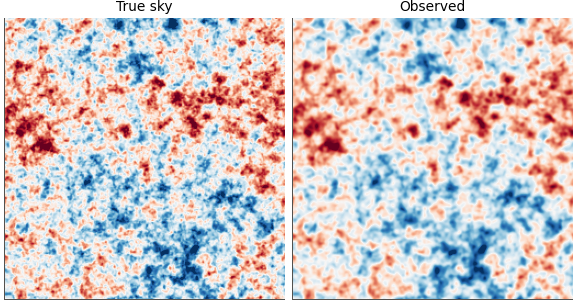

In [36]:
# Observe the CMB patch with an unknown beam.
sigma_secret = np.radians(np.random.default_rng(13).uniform(4, 12) / 60) / np.sqrt(8 * np.log(2))
ell_grid = wavenumbers(N, L, 2)
observed = np.fft.ifft2(np.fft.fft2(cmb) * np.exp(-ell_grid * (ell_grid + 1) * sigma_secret ** 2 / 2)).real

ps_plot.show_images([cmb, observed], ['True sky', 'Observed'], cmaps=['RdBu_r'] * 2, vmin=-300, vmax=300)

In [37]:
##############################
# YOU NEED TO EDIT THIS CELL #
##############################

# Estimate the beam FWHM in arcmin.
fwhm_estimate = None

if fwhm_estimate is not None:
    print(f'Estimated FWHM = {fwhm_estimate:.2f} arcmin')

## Summary

* The **power spectrum** $P_k = |X_k|^2/N^2$ is the squared amplitude of the Fourier transform. It shows how the **variance** of a signal is distributed over frequency or scale, and discards all of the phase information.
* By the **Wiener-Khinchin theorem**, the power spectrum and the **autocorrelation** (or correlation function) are a Fourier pair.
* For a **random** signal, the phases carry no information, and the expected power spectrum characterises the process. A **Gaussian random field** is completely described by its power spectrum.
* A single periodogram scatters by 100%. Averaging over $M$ segments, or over the $N_{\rm modes}$ in a shell of $|\mathbf{k}|$, reduces the scatter to $\sqrt{2/N_{\rm modes}}$, at the cost of resolution. Large scales contain few modes: **sample / cosmic variance**.
* For a set of points, the **two-point correlation function** $\xi(r)$ (excess pairs at separation $r$) and $P(k)$ are a Fourier pair. Discreteness adds **shot noise** $1/\bar{n}$.
* The **matter power spectrum** $P(k) = A k^{n_s} T^2(k)$ encodes the primordial fluctuations, the turnover at matter-radiation equality and the **BAO**, which appear as a peak at $r_s \approx 100\,h^{-1}\,\mathrm{Mpc}$ in the correlation function: a standard ruler.
* The **CMB power spectrum** $C_\ell$ uses spherical harmonics instead of plane waves. Its **acoustic peaks** measure the geometry, the baryon density and other parameters. In practice it is limited by cosmic variance on large scales and by the **beam** and **noise** on small scales. **Masks** mix multipoles: the **pseudo-$C_\ell$** of a masked map is corrected by inverting the mode-coupling matrix (**MASTER**).
* A **3x2pt** analysis combines **cosmic shear**, **galaxy-galaxy lensing** and **galaxy clustering** spectra between tomographic bins, computed from $P(k, z)$ with the **Limber approximation**. The combination breaks the degeneracy between galaxy bias and the amplitude of matter fluctuations.

## Further Resources

* W. Hu, [*CMB Introduction and Tutorials*](http://background.uchicago.edu/~whu/) (animated explanations of the acoustic peaks)
* S. Dodelson and F. Schmidt, [*Modern Cosmology*](https://doi.org/10.1016/C2017-0-01943-2) (2nd ed., 2020)
* D. Eisenstein and W. Hu, [*Baryonic Features in the Matter Transfer Function*](https://arxiv.org/abs/astro-ph/9709112), ApJ 496, 605 (1998)
* Planck Collaboration, [*Planck 2018 results. VI. Cosmological parameters*](https://arxiv.org/abs/1807.06209), A&A 641, A6 (2020)
* E. Hivon et al., [*MASTER of the CMB Anisotropy Power Spectrum*](https://arxiv.org/abs/astro-ph/0105302), ApJ 567, 2 (2002)
* D. Alonso et al., [*A unified pseudo-$C_\ell$ framework*](https://arxiv.org/abs/1809.09603), MNRAS 484, 4127 (2019) ([NaMaster](https://namaster.readthedocs.io/))
* M. Kilbinger, [*Cosmology with cosmic shear observations: a review*](https://arxiv.org/abs/1411.0115), Rep. Prog. Phys. 78, 086901 (2015)
* DES Collaboration, [*Dark Energy Survey Year 3 results: Cosmological constraints from galaxy clustering and weak lensing*](https://arxiv.org/abs/2105.13549), PRD 105, 023520 (2022)
* [CCL](https://ccl.readthedocs.io/): the Core Cosmology Library, which computes all of the 3x2pt spectra
* [CAMB](https://camb.info) and [CLASS](https://lesgourg.github.io/class_public/class.html): Boltzmann codes that compute the exact $P(k)$ and $C_\ell$
* [healpy](https://healpy.readthedocs.io/): spherical harmonic transforms and full-sky maps

---

## <font color='#fdbf00'>Hints</font>

**Exercise 1: Measure a Spectral Index**

1. A single periodogram is too noisy to fit: average first, *e.g.* with `bartlett`.
1. On a log-log plot, $P \propto f^{-\beta}$ is a straight line with slope $-\beta$. `np.polyfit` fits a straight line.
1. Leave out $f = 0$, where the logarithm is undefined.

<details><summary>Solution</summary>

```python
f, P = bartlett(mystery, 64)
keep = f > 0
slope, intercept = np.polyfit(np.log10(f[keep]), np.log10(P[keep]), 1)
beta_estimate = -slope
```
</details>

**Exercise 2: Measure a Telescope Beam**

1. Measure the power spectrum of `observed` with `radial_power_spectrum`, and compare it with the theory, `C_ell`.
1. The ratio is $B_\ell^2 = e^{-\ell(\ell+1)\sigma_b^2}$, so its logarithm is a straight line in $\ell(\ell+1)$ with slope $-\sigma_b^2$.
1. Even better: divide by the measured spectrum of the *true* sky, `cmb`, which removes the sample variance.
1. Finally, $\theta_{\rm FWHM} = \sqrt{8\ln 2}\,\sigma_b$, converted from radians to arcmin.

<details><summary>Solution</summary>

```python
ell_b, C_obs, _ = radial_power_spectrum(observed, L)
_, C_true, _ = radial_power_spectrum(cmb, L)
keep = ell_b < 1500
slope = np.polyfit(ell_b[keep] * (ell_b[keep] + 1), np.log(C_obs[keep] / C_true[keep]), 1)[0]
fwhm_estimate = np.degrees(np.sqrt(-slope * 8 * np.log(2))) * 60
```
</details>